# P2: ¿de qué tamaño debe ser cada ventana de tiempo?

**Objetivo:** elegir con datos el tamaño de la ventana en la que se predice el riesgo de P2 (30 minutos, 1, 2, 3 o 4 horas, o el día completo). Las instrucciones dejan la granularidad al equipo; el ML Canvas proponía 2 h sin justificarlo.

Al final (sección 11) también se elige **a qué hora se reinicia el inventario** estimado de cada estación.

**Idea:** sin inventario de bicicletas, aproximamos el riesgo con el **balance neto** de cada estación en cada ventana: `llegadas − salidas`. Si en una ventana salen muchas más bicis de las que llegan, comparado con la capacidad de la estación, se puede vaciar; si llegan muchas más, se puede llenar.

**Umbral provisional:** para comparar ventanas usamos `|neto| ≥ 50% de la capacidad` como "riesgo". **No es el umbral final** (esa es otra decisión); solo sirve para comparar los tamaños de ventana con la misma regla.

**Datos:** `data/interim/viajes.parquet` desde `FECHA_INICIO` (2022-03-01) y el catálogo de estaciones.

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici_mlops.config import FECHA_INICIO, INTERIM_DATA_DIR, RAW_DATA_DIR

UMBRAL_PROVISIONAL = 0.5  # fracción de la capacidad; solo para comparar ventanas

## 1. Estaciones y su capacidad

El catálogo trae la capacidad (`dpcapacity`, número de anclajes). Hay estaciones con capacidad 0: las quitamos porque no se puede dividir entre 0.

`set_index("id")` pone el id de la estación como índice para poder buscar la capacidad con `.map()` (el "BUSCARV" que vimos en `dataset.py`).

In [32]:
estaciones = pd.read_csv(RAW_DATA_DIR / "estaciones" / "nomenclatura_2026_09.csv")
print(f"Estaciones con capacidad 0: {(estaciones['dpcapacity'] == 0).sum()}")

estaciones = estaciones[estaciones["dpcapacity"] > 0].set_index("id")
estaciones["dpcapacity"].describe()

Estaciones con capacidad 0: 4


count    480.000000
mean      17.022917
std        3.843697
min       11.000000
25%       15.000000
50%       15.000000
75%       19.000000
max       39.000000
Name: dpcapacity, dtype: float64

## 2. Viajes desde la fecha de corte

Como en el notebook del periodo, leemos solo las columnas necesarias. `filters` lee solo los viajes desde `FECHA_INICIO` (definida en `config.py`).

In [33]:
viajes = pd.read_parquet(
    INTERIM_DATA_DIR / "viajes.parquet",
    columns=["inicio", "fin", "origen_id", "destino_id"],
    filters=[("inicio", ">=", pd.Timestamp(FECHA_INICIO))],
)
print(f"Viajes: {len(viajes):,}")

Viajes: 20,431,557


## 3. Salidas y llegadas por estación y media hora

- `.dt.floor("30min")` redondea cada fecha **hacia abajo** a la media hora: `08:47:12` → `08:30`. Así todos los viajes entre 8:30 y 8:59 caen en la misma media hora. Es la unidad más chica que comparamos; las ventanas más grandes se arman sumando medias horas.
- `groupby([columna1, columna2])` agrupa por **dos** cosas a la vez: estación **y** hora. `.size()` cuenta cuántos viajes hay en cada grupo.
- Una **salida** se cuenta en la estación de origen a la hora de inicio; una **llegada**, en la estación de destino a la hora de fin.

In [34]:
salidas = viajes.groupby(["origen_id", viajes["inicio"].dt.floor("30min")]).size()
llegadas = viajes.groupby(["destino_id", viajes["fin"].dt.floor("30min")]).size()

salidas.index.names = ["estacion", "hora"]
llegadas.index.names = ["estacion", "hora"]
salidas.head()

estacion  hora               
2         2022-03-01 06:30:00    1
          2022-03-01 07:00:00    2
          2022-03-01 07:30:00    1
          2022-03-01 08:00:00    2
          2022-03-01 08:30:00    2
dtype: int64

Ahora juntamos salidas y llegadas en una sola tabla.

- `pd.concat({...}, axis=1)` pone las dos series **lado a lado** como columnas (con los nombres `salidas` y `llegadas`), alineadas por estación y hora.
- Si en una hora hubo salidas pero ninguna llegada, la llegada queda vacía (`NaN`). `.fillna(0)` la cambia a 0, porque significa "no llegó nadie".
- Quitamos las estaciones que no están en el catálogo (o tienen capacidad 0) y agregamos la capacidad con `.map()`.

In [35]:
por_media_hora = pd.concat({"salidas": salidas, "llegadas": llegadas}, axis=1).fillna(0).reset_index()
por_media_hora = por_media_hora[por_media_hora["estacion"].isin(estaciones.index)]

por_media_hora["neto"] = por_media_hora["llegadas"] - por_media_hora["salidas"]
por_media_hora["capacidad"] = por_media_hora["estacion"].map(estaciones["dpcapacity"])
por_media_hora.head()

,estacion,hora,salidas,llegadas,neto,capacidad
0,2,2022-03-01 06:30:00,1.0,0.0,-1.0,15
1,2,2022-03-01 07:00:00,2.0,0.0,-2.0,15
2,2,2022-03-01 07:30:00,1.0,3.0,2.0,15
3,2,2022-03-01 08:00:00,2.0,2.0,0.0,15
4,2,2022-03-01 08:30:00,2.0,8.0,6.0,15


## 4. Medida 1: ¿cuánto duran las horas pico?

Si los desbalances fuertes duran unas 2–3 horas, una ventana mucho más larga los diluye y una mucho más corta los parte.

Calculamos, para días hábiles, el promedio del balance neto **en valor absoluto** (`.abs()`, sin signo) por hora del día: cuánto se desbalancea una estación típica en cada hora, sin importar si se vacía o se llena.

Como los conteos están por media hora, primero sumamos las dos medias horas de cada hora. Nota: solo cuenta las horas en que la estación tuvo al menos un viaje.

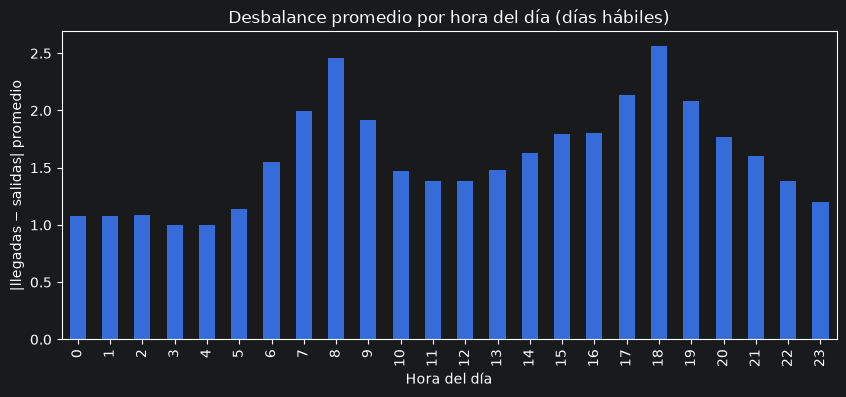

In [36]:
habiles = por_media_hora[por_media_hora["hora"].dt.dayofweek < 5]  # 0 = lunes ... 4 = viernes
neto_por_hora = habiles.groupby(["estacion", habiles["hora"].dt.floor("h")])["neto"].sum().reset_index()
desbalance_por_hora = neto_por_hora["neto"].abs().groupby(neto_por_hora["hora"].dt.hour).mean()

fig, ax = plt.subplots(figsize=(10, 4))
desbalance_por_hora.plot(kind="bar", ax=ax)
ax.set_title("Desbalance promedio por hora del día (días hábiles)")
ax.set_xlabel("Hora del día")
ax.set_ylabel("|llegadas − salidas| promedio")
plt.show()

## 5. Medida 2: ¿qué tan rara es la clase de riesgo con cada ventana?

Con ventanas muy cortas casi nunca se ve riesgo y el modelo tendría muy pocos ejemplos para aprender.

Para cada tamaño:

1. Agrupamos en ventanas con `dt.floor`: `dt.floor("120min")` redondea a bloques de 2 horas (00:00, 02:00, 04:00…) y `dt.floor("1440min")` agrupa el día completo. Usamos minutos para poder incluir ventanas de 30 minutos.
2. Sumamos el balance neto de cada estación en cada ventana.
3. Contamos las ventanas en que `neto / capacidad` pasa el umbral provisional.

El porcentaje se calcula sobre **todas** las ventanas posibles (también las que no tuvieron viajes): por cada estación, desde su primer hasta su último día con viajes.

In [37]:
dias_activa = por_media_hora.groupby("estacion")["hora"].agg(["min", "max"])
total_dias = ((dias_activa["max"].dt.normalize() - dias_activa["min"].dt.normalize()).dt.days + 1).sum()

minutos_por_ventana = [30, 60, 120, 180, 240, 1440]  # 1440 = día completo
filas = []
for minutos in minutos_por_ventana:
    por_ventana = por_media_hora.groupby(["estacion", por_media_hora["hora"].dt.floor(f"{minutos}min")]).agg(
        neto=("neto", "sum"), capacidad=("capacidad", "first")
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    total_ventanas = total_dias * 1440 / minutos
    se_vacia = (proporcion <= -UMBRAL_PROVISIONAL).sum()
    se_llena = (proporcion >= UMBRAL_PROVISIONAL).sum()
    filas.append(
        {
            "horas": minutos / 60,
            "ventanas_se_vacia": se_vacia,
            "ventanas_se_llena": se_llena,
            "pct_se_vacia": se_vacia / total_ventanas * 100,
            "pct_se_llena": se_llena / total_ventanas * 100,
        }
    )

pd.DataFrame(filas).set_index("horas").round(2)

,ventanas_se_vacia,ventanas_se_llena,pct_se_vacia,pct_se_llena
horas,,,,
0.5,11462,12779,0.04,0.05
1.0,28932,30543,0.21,0.22
2.0,60364,61984,0.86,0.89
3.0,84452,77690,1.82,1.67
4.0,91983,88068,2.64,2.52
24.0,63803,58606,10.97,10.08


## 6. Medida 3: ¿una estación tiene los dos riesgos el mismo día?

Si pasa seguido, una ventana de un día completo pierde información: no puede decir "se vacía en la mañana **y** se llena en la tarde".

Para cada ventana menor a un día marcamos si la estación se vació o se llenó, y luego revisamos por estación y día si tuvo alguno (`.any()`) de cada tipo.

In [38]:
filas = []
for minutos in [30, 60, 120, 180, 240]:  # sin el día completo
    por_ventana = (
        por_media_hora.groupby(["estacion", por_media_hora["hora"].dt.floor(f"{minutos}min")])
        .agg(neto=("neto", "sum"), capacidad=("capacidad", "first"))
        .reset_index()
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    por_ventana["se_vacia"] = proporcion <= -UMBRAL_PROVISIONAL
    por_ventana["se_llena"] = proporcion >= UMBRAL_PROVISIONAL

    por_dia = por_ventana.groupby(["estacion", por_ventana["hora"].dt.normalize()])[
        ["se_vacia", "se_llena"]
    ].any()
    dias_con_riesgo = (por_dia["se_vacia"] | por_dia["se_llena"]).sum()
    dias_con_ambos = (por_dia["se_vacia"] & por_dia["se_llena"]).sum()
    filas.append(
        {
            "horas": minutos / 60,
            "dias_con_riesgo": dias_con_riesgo,
            "dias_con_ambos": dias_con_ambos,
            "pct_con_ambos": dias_con_ambos / dias_con_riesgo * 100,
        }
    )

pd.DataFrame(filas).set_index("horas").round(1)

,dias_con_riesgo,dias_con_ambos,pct_con_ambos
horas,,,
0.5,16471,1602,9.7
1.0,42147,4758,11.3
2.0,88546,14146,16.0
3.0,118271,22453,19.0
4.0,133179,25351,19.0


## 7. ¿Dónde empiezan los bloques? Pares contra impares

La gráfica de la medida 1 muestra picos de **7 a 9 h** y de **17 a 19 h**. Pero `dt.floor("2h")` arma bloques que empiezan en horas **pares** (6–8, 8–10, …, 16–18, 18–20), así que cada pico queda **partido en dos bloques** y su desbalance se reparte entre ambos.

Si los bloques empiezan en horas **impares** (7–9, 9–11, …, 17–19), cada pico queda en un solo bloque. Comparamos las dos versiones con las medidas 2 y 3.

**Cómo se desplazan los bloques:** `dt.floor` siempre empieza en horas pares, así que:

1. Restamos 1 hora: las `07:30` pasan a `06:30`.
2. Redondeamos a bloques de 2 h: `06:30` → `06:00`.
3. Sumamos la hora de vuelta: `06:00` → `07:00`.

Resultado: todo lo que pasa entre 7:00 y 8:59 cae en el bloque que empieza a las `07:00`.

La función `medir_bloques_2h` hace las medidas 2 y 3 para un desfase dado (0 = pares, 1 = impares), para no repetir el código dos veces.

In [39]:
def medir_bloques_2h(desfase_horas):
    desfase = pd.Timedelta(hours=desfase_horas)
    inicio_bloque = (por_media_hora["hora"] - desfase).dt.floor("2h") + desfase

    por_ventana = (
        por_media_hora.groupby(["estacion", inicio_bloque])
        .agg(neto=("neto", "sum"), capacidad=("capacidad", "first"))
        .reset_index()
    )
    proporcion = por_ventana["neto"] / por_ventana["capacidad"]
    por_ventana["se_vacia"] = proporcion <= -UMBRAL_PROVISIONAL
    por_ventana["se_llena"] = proporcion >= UMBRAL_PROVISIONAL

    por_dia = por_ventana.groupby(["estacion", por_ventana["hora"].dt.normalize()])[
        ["se_vacia", "se_llena"]
    ].any()
    dias_con_riesgo = (por_dia["se_vacia"] | por_dia["se_llena"]).sum()
    total_ventanas = total_dias * 24 / 2

    return {
        "ventanas_se_vacia": por_ventana["se_vacia"].sum(),
        "ventanas_se_llena": por_ventana["se_llena"].sum(),
        "pct_se_vacia": por_ventana["se_vacia"].sum() / total_ventanas * 100,
        "pct_se_llena": por_ventana["se_llena"].sum() / total_ventanas * 100,
        "pct_dias_con_ambos": (por_dia["se_vacia"] & por_dia["se_llena"]).sum()
        / dias_con_riesgo
        * 100,
    }


pd.DataFrame(
    {
        "pares (6–8, 8–10, …)": medir_bloques_2h(0),
        "impares (7–9, 9–11, …)": medir_bloques_2h(1),
    }
).round(2)

,"pares (6–8, 8–10, …)","impares (7–9, 9–11, …)"
ventanas_se_vacia,60364.00,62379.00
ventanas_se_llena,61984.00,59344.00
pct_se_vacia,0.86,0.89
pct_se_llena,0.89,0.85
pct_dias_con_ambos,15.98,16.08


## 8. Medida 4: ¿cuánto dura un viaje?

Si los viajes duran mucho comparado con la ventana, muchas bicis salen en una ventana y llegan en la siguiente: la ventana ve la salida pero no la llegada. Medimos:

- La duración de los viajes en minutos (`fin − inicio`; `.dt.total_seconds() / 60` convierte la diferencia de fechas a minutos).
- Qué porcentaje de viajes **termina en una ventana distinta** a la que empezó, para cada tamaño.

In [40]:
duracion_min = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60
print("Duración de los viajes (minutos), por percentil:")
print(duracion_min.quantile([0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

cruzan = {
    minutos / 60: (
        viajes["inicio"].dt.floor(f"{minutos}min") != viajes["fin"].dt.floor(f"{minutos}min")
    ).mean()
    * 100
    for minutos in [30, 60, 120, 180, 240]
}
pd.Series(cruzan, name="pct_termina_en_otra_ventana").round(1)

Duración de los viajes (minutos), por percentil:
0.25     5.7
0.50     9.4
0.75    14.8
0.95    24.2
0.99    32.8
dtype: float64


0.5    35.0
1.0    17.5
2.0     8.6
3.0     6.1
4.0     4.4
Name: pct_termina_en_otra_ventana, dtype: float64

## 9. Medida 5: ¿cuánto dura un evento de desbalance?

Las medidas anteriores descartan 30 minutos, 1 hora y el día completo, pero no distinguen entre 2, 3 y 4 horas. Para eso medimos **cuánto dura un evento** de vaciado o llenado.

**Ejemplo:** una estación se vacía en la mañana. Bicis que se van (salidas − llegadas) cada media hora:

```
6:00  6:30  7:00  7:30  8:00  8:30  9:00  9:30
  0     1     4     5     5     4     1     0      → en total se van 20
```

- En la **mejor hora** (7:30–8:30) se van 10 de 20: **50%**.
- En las **mejores 2 horas** (7:00–9:00) se van 18 de 20: **90%**.
- En las **mejores 3 horas** se van las 20: **100%**.

Hacemos esa cuenta para todas las ventanas con riesgo. Si las mejores 2 horas de una ventana de 3 o 4 horas ya concentran casi todo el desbalance, las horas extra solo diluyen el "cuándo".

**Cómo lo calcula la función `concentracion`:**

1. `bloque`: el inicio de la ventana grande; `posicion`: qué media hora es dentro del bloque (0, 1, 2, …).
2. `.transform("sum")` calcula el total del bloque y lo pone **en cada fila** (a diferencia de `.sum()`, que deja una fila por grupo). Así podemos quedarnos solo con los bloques con riesgo.
3. `pivot_table` deja una fila por bloque y una columna por media hora, como en el ejemplo.
4. Sumamos cada grupo de medias horas consecutivas (`.iloc[:, i : i + n]`) para obtener todos los sub-bloques posibles y nos quedamos con el más cargado **en la dirección del riesgo** (`np.sign` da −1 si la estación se vacía y +1 si se llena).
5. Dividimos entre el total del bloque. `.clip(0, 1)` limita el resultado entre 0% y 100%.

In [41]:
def concentracion(minutos_ventana, minutos_sub):
    datos = por_media_hora[["estacion", "hora", "neto", "capacidad"]].copy()
    datos["bloque"] = datos["hora"].dt.floor(f"{minutos_ventana}min")
    datos["posicion"] = (datos["hora"] - datos["bloque"]) // pd.Timedelta("30min")

    # Solo los bloques con riesgo
    datos["neto_bloque"] = datos.groupby(["estacion", "bloque"])["neto"].transform("sum")
    datos = datos[datos["neto_bloque"].abs() / datos["capacidad"] >= UMBRAL_PROVISIONAL]

    # Una fila por bloque, una columna por media hora
    ancho = datos.pivot_table(
        index=["estacion", "bloque"], columns="posicion", values="neto", aggfunc="sum", fill_value=0
    ).reindex(columns=range(minutos_ventana // 30), fill_value=0)

    total = ancho.sum(axis=1)
    signo = np.sign(total)
    n = minutos_sub // 30
    sub_bloques = pd.concat(
        [ancho.iloc[:, i : i + n].sum(axis=1) for i in range(ancho.shape[1] - n + 1)], axis=1
    )
    mejor = sub_bloques.mul(signo, axis=0).max(axis=1)
    proporcion = (mejor / (total * signo)).clip(0, 1)

    return {
        "ventanas_con_riesgo": len(proporcion),
        "mediana_pct_en_mejor_sub_bloque": proporcion.median() * 100,
        "pct_ventanas_con_80_o_mas": (proporcion >= 0.8).mean() * 100,
    }


pd.DataFrame(
    {
        "ventana 2 h, mejor 1 h": concentracion(120, 60),
        "ventana 3 h, mejor 2 h": concentracion(180, 120),
        "ventana 4 h, mejor 2 h": concentracion(240, 120),
        "ventana 4 h, mejor 3 h": concentracion(240, 180),
    }
).T.round(1)

,ventanas_con_riesgo,mediana_pct_en_mejor_sub_bloque,pct_ventanas_con_80_o_mas
"ventana 2 h, mejor 1 h",122348.0,75.0,39.8
"ventana 3 h, mejor 2 h",162142.0,88.2,71.8
"ventana 4 h, mejor 2 h",180051.0,84.6,60.7
"ventana 4 h, mejor 3 h",180051.0,100.0,88.5


## 10. Conclusión: ventanas de 2 horas

Comparamos ventanas de 30 minutos, 1, 2, 3 y 4 horas y el día completo (en las tablas, `horas = 0.5` es 30 minutos y `24` el día completo):

| Medida | Resultado | Qué implica |
|---|---|---|
| 1. Horas pico | Picos de 7 a 9 h y de 17 a 19 h en días hábiles; duran ~2–3 h | Ventanas de 2 o 3 h siguen la forma de los picos |
| 2. Rareza del riesgo | 30 min: 0.04% de ventanas con riesgo; 1 h: 0.2%; 2 h: ~0.9% (~60 mil por clase); 3 h: ~1.8%; día: ~11% | **Descarta 30 min y 1 h**: muy pocos ejemplos de riesgo |
| 3. Ambos riesgos el mismo día | Con ventanas de 2 a 4 h, 16–19% de los días con riesgo tienen los dos tipos | **Descarta el día completo**: no puede representar "se vacía en la mañana y se llena en la tarde" ni decir a qué hora ir |
| Bloques pares vs. impares | Sin diferencia (0.86% vs. 0.89%) | No importa dónde empiecen los bloques; se usan los pares (`dt.floor`) |
| 4. Duración de los viajes | Mediana de ~9 min; 99% dura menos de 33 min. Terminan en otra ventana: 35% con 30 min, 17.5% con 1 h, 8.6% con 2 h | Con 2 h o más, la gran mayoría de los viajes empieza y termina en la misma ventana |
| 5. Duración de los eventos | En ventanas con riesgo, el mejor sub-bloque concentra (mediana) el 75% del desbalance si es de 1 h, 85–88% si es de 2 h y 100% si es de 3 h | Un evento dura entre 2 y 3 horas: **1 h lo corta**; 2 h captura su núcleo; 3 h lo captura completo |

Un evento de desbalance dura entre 2 y 3 horas. **Elegimos 2 horas porque el objetivo de P2 es saber cuándo una estación estará en riesgo**: 2 horas captura el núcleo del evento (85–88% del desbalance) con más precisión sobre el momento que 3 horas, que lo captura completo pero diluye cuándo ocurre. Además deja ~60 mil ejemplos por clase de riesgo y coincide con el ML Canvas.

**Limitación:** estos porcentajes usan un umbral provisional (50% de la capacidad) y el balance de cada ventana por separado. La etiqueta final de P2 puede usar otro umbral y el inventario acumulado, así que los porcentajes cambiarán; la comparación entre tamaños de ventana sigue siendo válida porque todos se midieron con la misma regla.

**Otros hallazgos para después:** 3.6% de los viajes dura menos de 1 minuto y 45 viajes duran más de 24 horas. Hay que revisar si son viajes válidos.

## 11. Otra decisión de P2: ¿a qué hora se reinicia el inventario?

Para la etiqueta, el inventario estimado de cada estación se reinicia una vez al día al 50% de su capacidad (ver `references/decisiones_p2.md`, decisión 4). El reinicio debe hacerse a la hora con **menos actividad**, para suponer que ahí ocurre el rebalanceo sin cortar viajes a la mitad.

La gráfica de la medida 1 mide el desbalance, no la actividad. Aquí contamos directamente **cuántos viajes empiezan en cada hora del día**, en promedio por día.

In [42]:
dias = viajes["inicio"].dt.normalize().nunique()
viajes_por_hora = viajes["inicio"].dt.hour.value_counts().sort_index()

pd.DataFrame(
    {
        "viajes_por_dia": (viajes_por_hora / dias).round(0),
        "pct_del_total": (viajes_por_hora / viajes_por_hora.sum() * 100).round(2),
    }
)

,viajes_por_dia,pct_del_total
inicio,,
0,80.0,0.66
1,2.0,0.02
2,0.0,0.00
3,0.0,0.00
4,0.0,0.00
5,84.0,0.68
6,321.0,2.63
7,646.0,5.30
8,935.0,7.66


Para cada hora candidata contamos cuántos viajes están **a medio camino** en ese momento (empezaron antes y terminan después). Esos viajes quedarían cortados por el reinicio.

`corte` es la hora candidata en el día en que empezó el viaje. Un viaje que empieza a las 23:50 y termina a las 00:10 del día siguiente cruza la medianoche de **ese día siguiente**, por eso también revisamos `corte + 1 día`.

In [43]:
un_dia = pd.Timedelta(days=1)
en_curso = {}
for hora in [0, 2, 3, 4, 5]:
    corte = viajes["inicio"].dt.normalize() + pd.Timedelta(hours=hora)
    cruza_hoy = (viajes["inicio"] < corte) & (viajes["fin"] > corte)
    cruza_manana = (viajes["inicio"] < corte + un_dia) & (viajes["fin"] > corte + un_dia)
    en_curso[f"{hora:02d}:00"] = (cruza_hoy | cruza_manana).sum() / dias

pd.Series(en_curso, name="viajes_en_curso_por_dia").round(1)

00:00    22.6
02:00     0.9
03:00     0.4
04:00     0.4
05:00     0.4
Name: viajes_en_curso_por_dia, dtype: float64

### Conclusión: reinicio a las 4:00

- Entre la **1:00 y las 5:00 casi no hay viajes** (0 por día de 2:00 a 4:59): el sistema prácticamente no opera en ese horario.
- A las **00:00** hay ~23 viajes por día a medio camino; a las 3:00 y 4:00, prácticamente ninguno.
- Se elige **4:00**: es la última hora sin actividad antes de que el servicio arranque, no corta viajes y coincide con el inicio de un bloque de 2 horas (04:00–06:00). Cualquier hora entre 2:00 y 4:00 daría el mismo resultado.

Esto también explica el desbalance de ~1.0 de madrugada en la gráfica de la medida 1: casi no hay viajes a esas horas, y una hora con un solo viaje ya tiene un desbalance de 1.